# 03 — аналіз SSL-претренування ViT-S/16 (MAE + InfoNCE)

Ноутбук лише читає артефакти: `runs/ssl_*/` (`metrics.csv`, `config.yaml`, `recon/*.png`), `reports/tables/probe_<tag>.json` та `runs/probe/<tag>/features_val.pt`, і будує графіки функціями з `malaria_ssl.ssl.viz`. Probe: fit на train-кропах, оцінка на val-кропах; test не використовується.

Розділи «Криві втрат» … «PCA» показують усі `runs/ssl_*` (sweep + фінальні запуски). Фінальні запуски (`ssl_joint`, `ssl_mae_only`, `ssl_con_only`, 100 епох) окремо порівнюються в кінці ноутбука. Якщо `runs/ssl_*` немає, показуються dry runs (`dry_b_*`).

Як отримати артефакти:
```
python scripts/pretrain.py --config configs/ssl/joint.yaml
python scripts/probe.py --run runs/ssl_joint
python scripts/probe.py --ref random
python scripts/probe.py --ref imagenet
```

In [1]:
import pandas as pd

from malaria_ssl.ssl import viz
from malaria_ssl.utils.config import resolve_path

pd.set_option('display.precision', 3)
runs = viz.find_ssl_runs('ssl_')
FALLBACK = not runs  # until the real runs exist: short smokes of the three modes
if FALLBACK:
    runs = [viz.load_ssl_run(resolve_path('runs') / n) for n in ('dry_b_joint', 'dry_b_mae_only', 'dry_b_con_only')]
overfit = viz.find_ssl_runs('dry_a_overfit_mae')
probes = viz.load_probes()
print('FALLBACK (dry runs only):', FALLBACK)
print('runs:', [r['name'] for r in runs])
print('probes:', [p['tag'] for p in probes])

C:\Users\Alex\miniconda3\envs\medthesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FALLBACK (dry runs only): False
runs: ['ssl_con_only', 'ssl_joint', 'ssl_mae_only', 'ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']
probes: ['ref_imagenet', 'ref_random_init', 'ssl_con_only', 'ssl_joint', 'ssl_mae_only', 'ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']


## Криві втрат

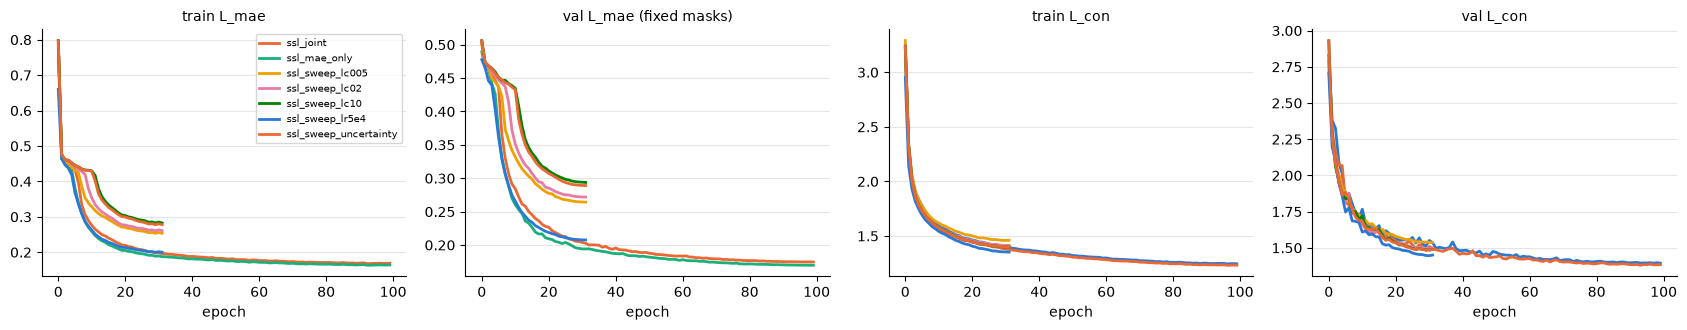

In [2]:
viz.plot_losses(runs);

## Ефективні ваги, learning rate, норма градієнта

Для `uncertainty` ваги = exp(−s_i); для `fixed` — λ з конфігу.

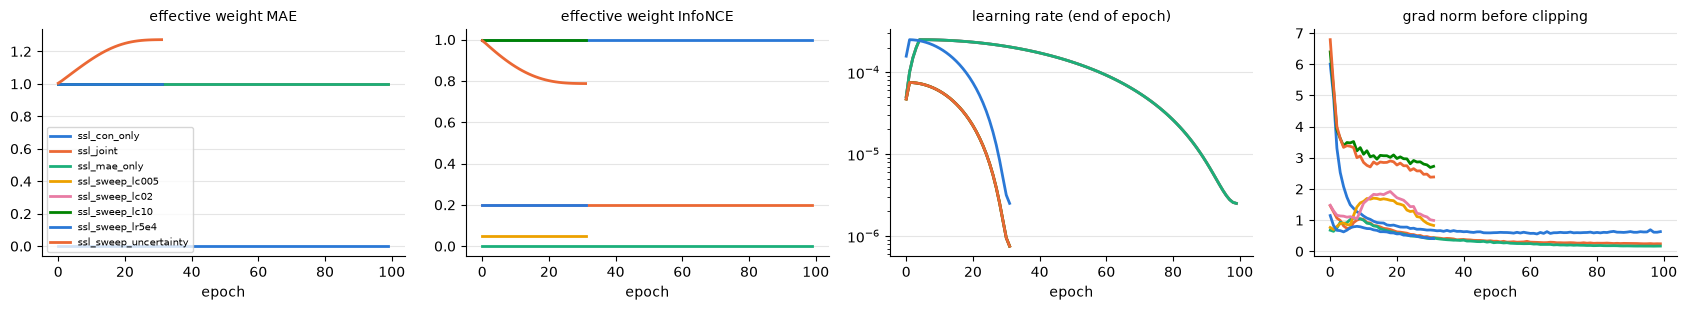

In [3]:
viz.plot_weights_lr(runs);

## Діагностика колапсу (фіксовані val-пари)

`std × √d` ≈ 1 — ембединги розкидані по сфері, → 0 — повний колапс; effective rank ловить розмірнісний колапс.

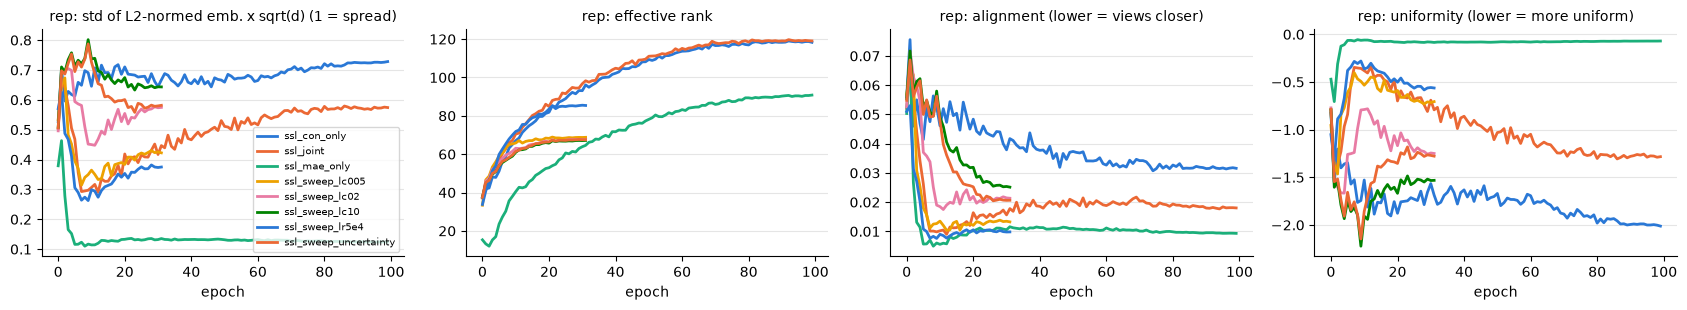

In [4]:
viz.plot_collapse(runs, 'rep');

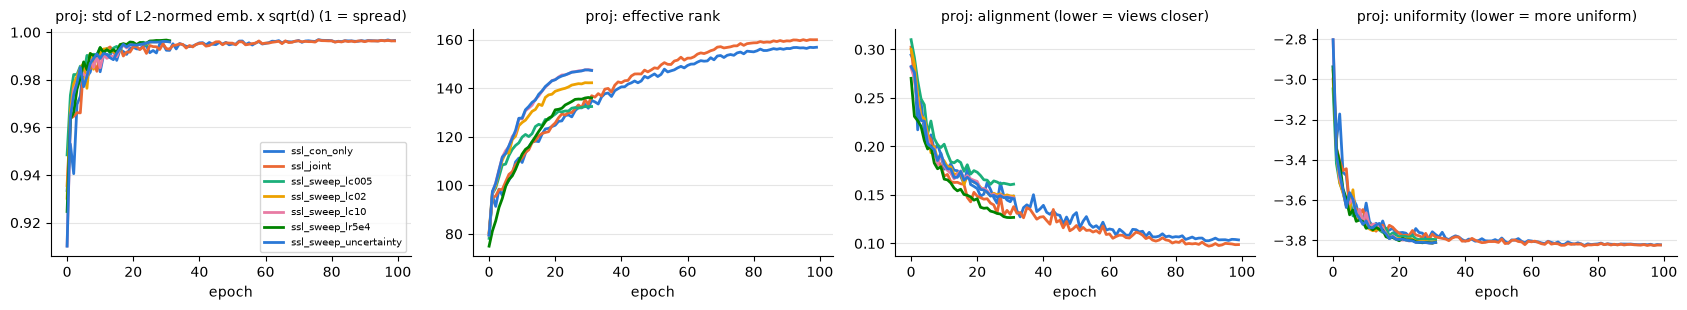

In [5]:
viz.plot_collapse([r for r in runs if 'proj/erank' in r['history']], 'proj');

## Light probe під час тренування

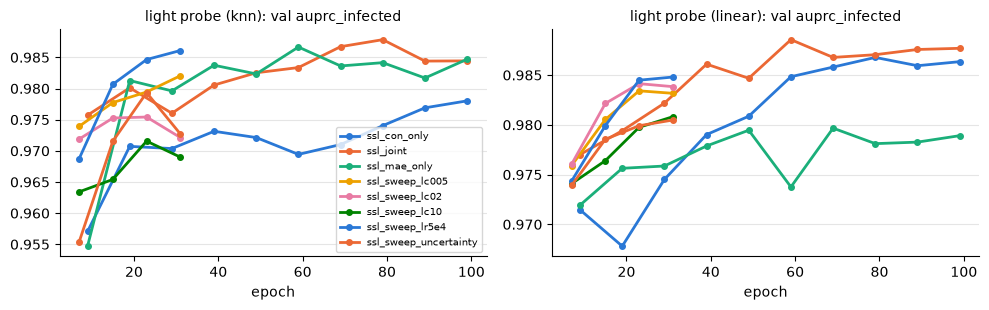

In [6]:
viz.plot_light_probe(runs, 'auprc_infected');

## Реконструкції MAE (рядки: оригінал | маска | реконструкція)

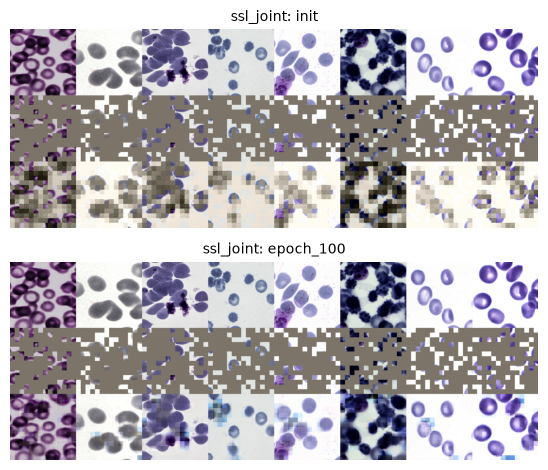

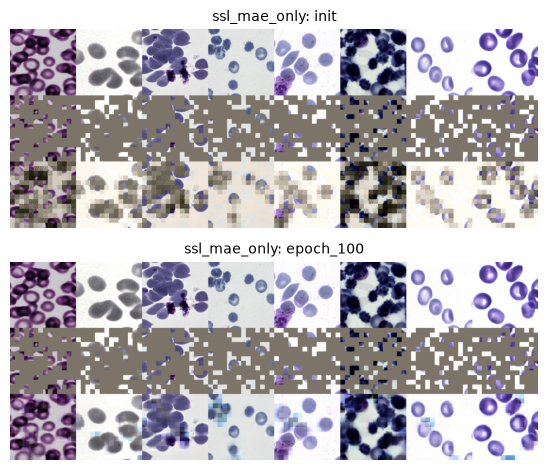

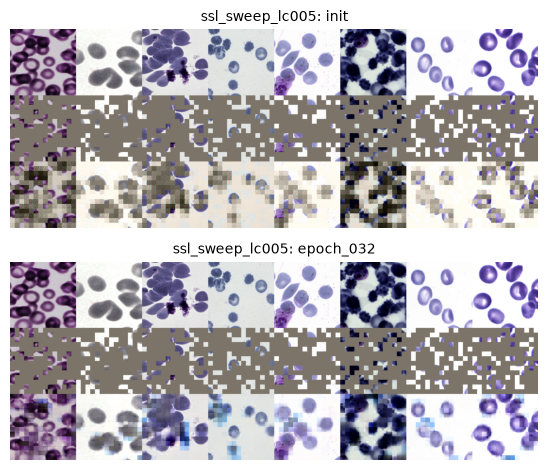

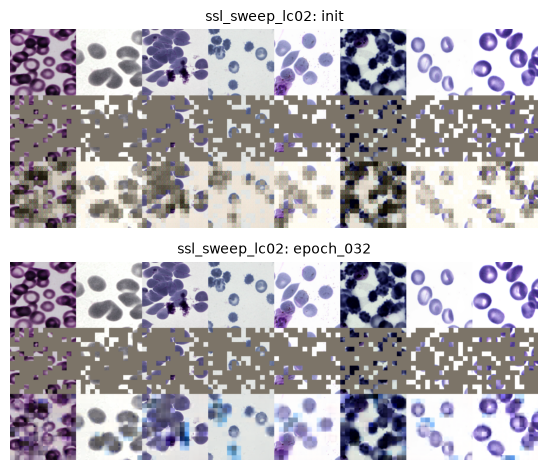

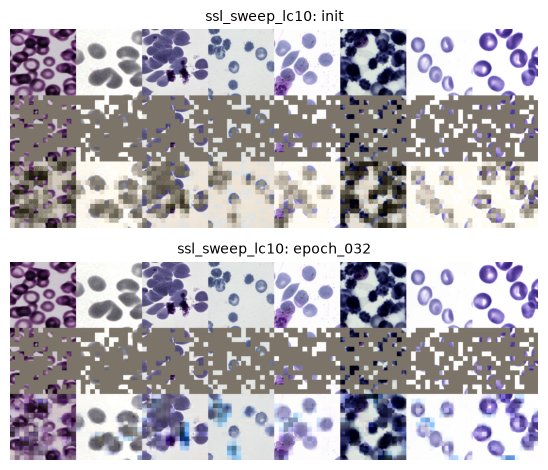

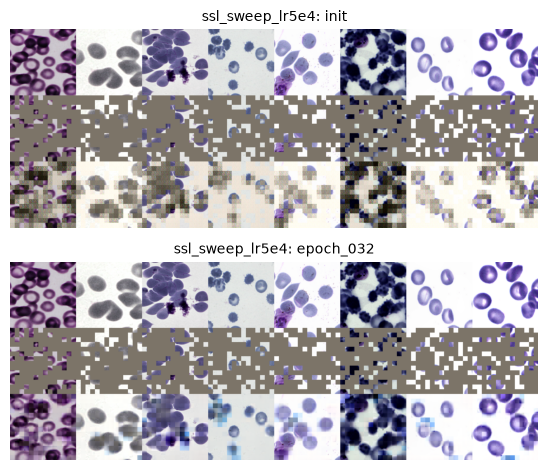

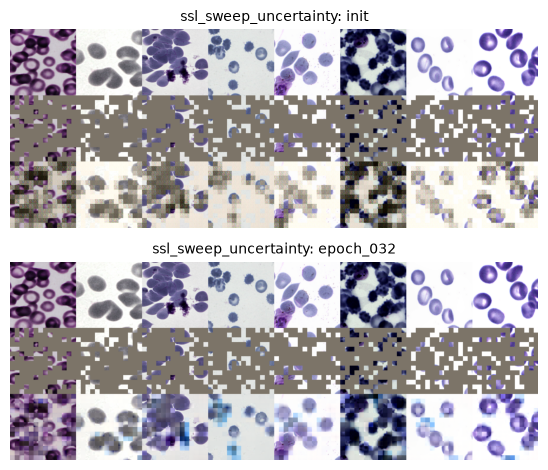

In [7]:
for r in runs:
    if r['recon']:
        viz.show_recon(r, (0, -1))

### Dry run (a): overfit MAE на 64 фіксованих train-кропах (без аугментацій)

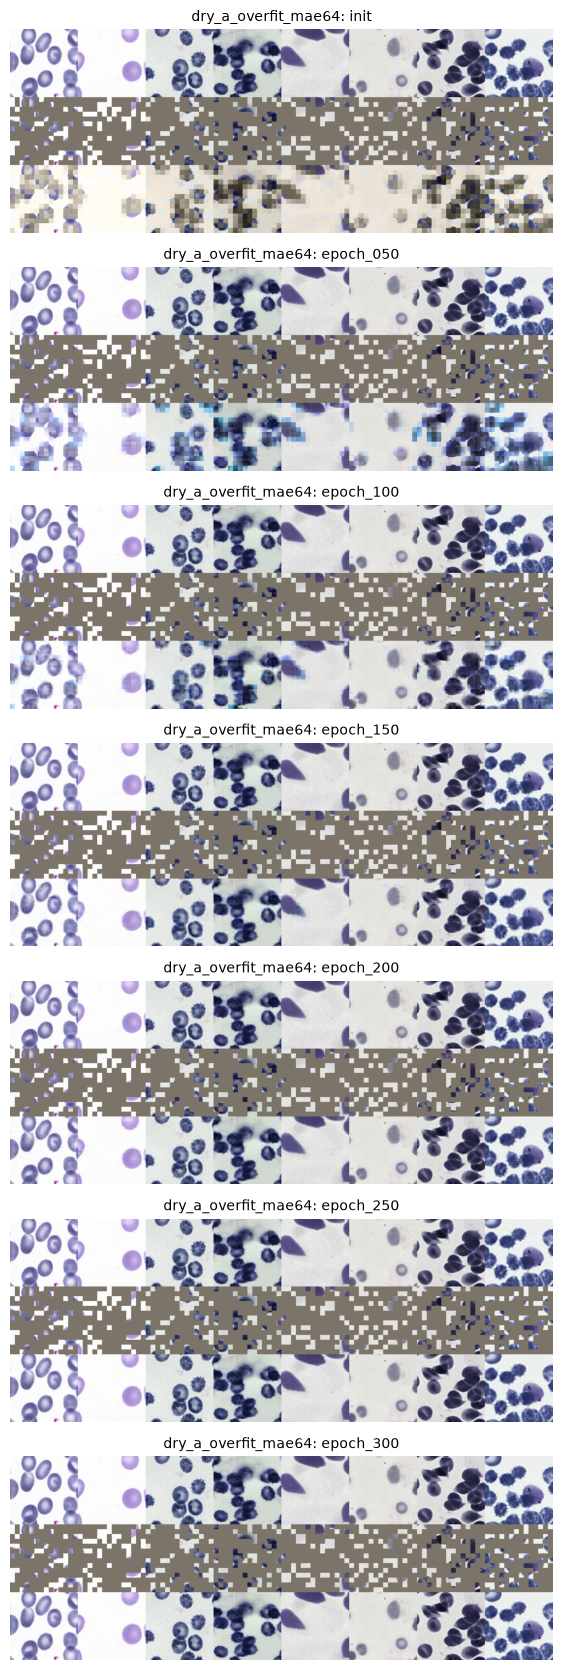

In [8]:
for r in overfit:
    viz.show_recon(r, tuple(range(len(r['recon']))))

## Probe: усі енкодери та референси (val-кропи, 100% міток, 95% bootstrap CI по зображеннях)

In [9]:
viz.probe_table(probes)

,encoder,method,auroc_infected,auroc_infected_CI95,auprc_infected,auprc_infected_CI95,balanced_acc,balanced_acc_CI95,macro_f1,macro_f1_CI95
0,ref_imagenet,knn,0.993,"[0.986, 0.997]",0.971,"[0.952, 0.985]",0.616,"[0.546, 0.686]",0.683,"[0.602, 0.746]"
1,ref_imagenet,linear,0.997,"[0.995, 0.998]",0.981,"[0.972, 0.989]",0.736,"[0.676, 0.797]",0.646,"[0.589, 0.696]"
2,ref_random_init,knn,0.928,"[0.908, 0.944]",0.730,"[0.660, 0.787]",0.437,"[0.371, 0.508]",0.465,"[0.384, 0.536]"
3,ref_random_init,linear,0.986,"[0.980, 0.991]",0.924,"[0.883, 0.954]",0.702,"[0.630, 0.765]",0.515,"[0.460, 0.567]"
4,ssl_con_only,knn,0.996,"[0.991, 0.999]",0.978,"[0.959, 0.992]",0.759,"[0.685, 0.826]",0.770,"[0.697, 0.827]"
5,ssl_con_only,linear,0.998,"[0.995, 0.999]",0.986,"[0.971, 0.996]",0.863,"[0.817, 0.901]",0.732,"[0.676, 0.780]"
6,ssl_joint,knn,0.997,"[0.992, 0.999]",0.984,"[0.969, 0.996]",0.781,"[0.713, 0.843]",0.789,"[0.730, 0.838]"
7,ssl_joint,linear,0.996,"[0.990, 0.999]",0.988,"[0.974, 0.996]",0.859,"[0.808, 0.899]",0.728,"[0.671, 0.776]"
8,ssl_mae_only,knn,0.997,"[0.991, 0.999]",0.985,"[0.969, 0.996]",0.693,"[0.626, 0.755]",0.714,"[0.649, 0.766]"
9,ssl_mae_only,linear,0.996,"[0.989, 0.999]",0.979,"[0.956, 0.993]",0.824,"[0.770, 0.872]",0.705,"[0.655, 0.750]"


## Stain-shifted probe

Ті самі класифікатори (fit на ЧИСТИХ train-кропах) оцінюються на val-кропах після фіксованого seeded фотометричного зсуву: HED (σ 0.08), яскравість/контраст/насиченість ±0.3, hue ±0.05, легке розмиття, JPEG 30–60 (`probe.stain_shift` у `configs/ssl/probe.yaml`). Зсув один на зображення, test не використовується. Зсув сильніший за SSL-аугментації, але SSL їх бачив — це тест інваріантності, а не відтворення test-домену.

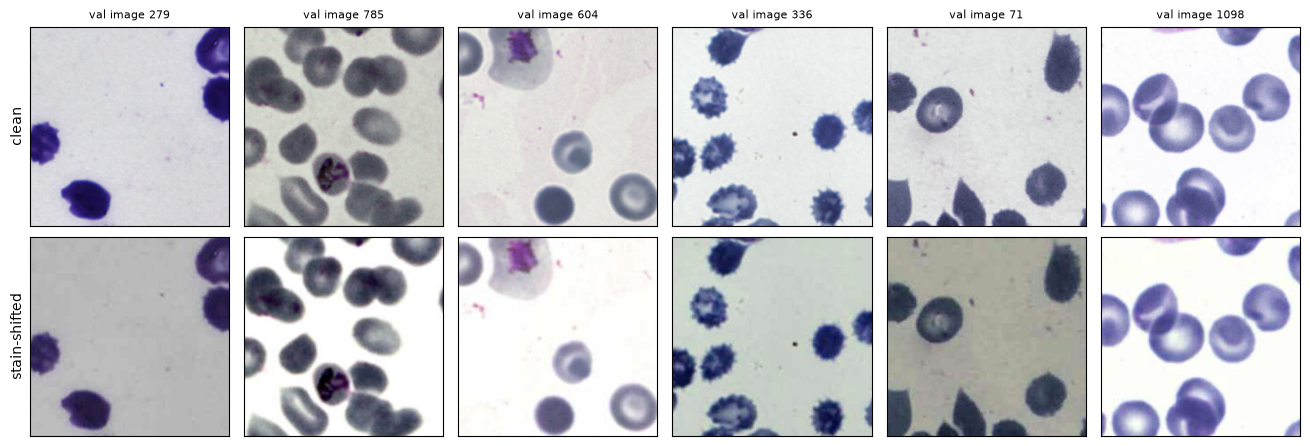

In [10]:
viz.show_stain_shift();

In [11]:
viz.stain_table(probes)

,encoder,method,auprc_infected_clean,auprc_infected_clean_CI95,auprc_infected_stain,auprc_infected_stain_CI95,auprc_infected_drop,macro_f1_clean,macro_f1_clean_CI95,macro_f1_stain,macro_f1_stain_CI95,macro_f1_drop
0,ref_imagenet,knn,0.971,"[0.952, 0.985]",0.905,"[0.874, 0.932]",6.592e-02,0.683,"[0.602, 0.746]",0.535,"[0.455, 0.602]",0.148
1,ref_imagenet,linear,0.981,"[0.972, 0.989]",0.943,"[0.921, 0.961]",3.858e-02,0.646,"[0.589, 0.696]",0.530,"[0.471, 0.586]",0.116
2,ref_random_init,knn,0.730,"[0.660, 0.787]",0.364,"[0.302, 0.437]",3.663e-01,0.465,"[0.384, 0.536]",0.294,"[0.244, 0.344]",0.171
3,ref_random_init,linear,0.924,"[0.883, 0.954]",0.525,"[0.421, 0.638]",3.988e-01,0.515,"[0.460, 0.567]",0.294,"[0.256, 0.336]",0.221
4,ssl_con_only,knn,0.978,"[0.959, 0.992]",0.969,"[0.948, 0.986]",9.039e-03,0.770,"[0.697, 0.827]",0.725,"[0.653, 0.784]",0.045
5,ssl_con_only,linear,0.986,"[0.971, 0.996]",0.982,"[0.968, 0.993]",4.067e-03,0.732,"[0.676, 0.780]",0.645,"[0.591, 0.694]",0.086
6,ssl_joint,knn,0.984,"[0.969, 0.996]",0.985,"[0.970, 0.995]",-6.996e-04,0.789,"[0.730, 0.838]",0.778,"[0.711, 0.832]",0.011
7,ssl_joint,linear,0.988,"[0.974, 0.996]",0.984,"[0.971, 0.992]",4.018e-03,0.728,"[0.671, 0.776]",0.662,"[0.602, 0.719]",0.066
8,ssl_mae_only,knn,0.985,"[0.969, 0.996]",0.977,"[0.961, 0.990]",7.857e-03,0.714,"[0.649, 0.766]",0.632,"[0.554, 0.686]",0.082
9,ssl_mae_only,linear,0.979,"[0.956, 0.993]",0.946,"[0.922, 0.966]",3.312e-02,0.705,"[0.655, 0.750]",0.553,"[0.495, 0.606]",0.152


## Вибір λ (sweep)

Порядок: linear AUPRC infected (чисті val) → stain-shifted linear AUPRC → linear AUPRC при 10% міток → linear macro-F1. Нічия = значення в межах інтервалу лідера (95% CI; для 10% — mean − std по seeds).

In [12]:
sweep = [p for p in probes if p['tag'].startswith('ssl_sweep_')]
if sweep:
    table, sel = viz.selection_table(sweep)
    print('winner:', sel['winner'])
    for s in sel['steps']:
        print(f"  {s['criterion']}: leader {s['leader']}, tied {s['tied']}")
    display(table)
else:
    print('no sweep probes yet (reports/tables/probe_ssl_sweep_*.json)')

winner: ssl_sweep_lc005
  auprc_clean: leader ssl_sweep_lr5e4, tied ['ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']
  auprc_stain: leader ssl_sweep_lc02, tied ['ssl_sweep_lc005', 'ssl_sweep_lc02', 'ssl_sweep_lc10', 'ssl_sweep_lr5e4', 'ssl_sweep_uncertainty']
  auprc_10pct: leader ssl_sweep_lc005, tied ['ssl_sweep_lc005']


,auprc_clean,auprc_stain,auprc_10pct,macro_f1,winner
ssl_sweep_lc005,0.983,0.968,0.966,0.692,True
ssl_sweep_lc02,0.984,0.974,0.961,0.670,False
ssl_sweep_lc10,0.981,0.963,0.952,0.691,False
ssl_sweep_lr5e4,0.985,0.973,0.958,0.712,False
ssl_sweep_uncertainty,0.980,0.963,0.952,0.699,False


## Recall по класах (linear probe)

In [13]:
viz.per_class_recall_table(probes, 'linear')

,encoder,class,n_val,recall,CI95
0,ref_imagenet,red blood cell,2000,0.963,"[0.953, 0.972]"
1,ref_imagenet,leukocyte,14,0.929,"[0.778, 1.000]"
2,ref_imagenet,gametocyte,20,0.550,"[0.333, 0.769]"
3,ref_imagenet,ring,49,0.735,"[0.581, 0.862]"
4,ref_imagenet,trophozoite,204,0.721,"[0.650, 0.788]"
5,ref_imagenet,schizont,25,0.520,"[0.320, 0.710]"
6,ref_random_init,red blood cell,2000,0.910,"[0.885, 0.931]"
7,ref_random_init,leukocyte,14,0.643,"[0.368, 0.900]"
8,ref_random_init,gametocyte,20,0.700,"[0.500, 0.895]"
9,ref_random_init,ring,49,0.878,"[0.763, 0.961]"


## Low-label: 1% / 10% / 100% міток train-кропів

,encoder,method,fraction,mean,std,n_train
1,ref_imagenet,knn,0.01,0.888,0.021,60.0
2,ref_imagenet,knn,0.10,0.941,0.006,593.0
0,ref_imagenet,knn,1.00,0.971,0.000,NaN
4,ref_imagenet,linear,0.01,0.914,0.013,60.0
5,ref_imagenet,linear,0.10,0.978,0.004,593.0
3,ref_imagenet,linear,1.00,0.981,0.000,NaN
7,ref_random_init,knn,0.01,0.276,0.026,60.0
8,ref_random_init,knn,0.10,0.486,0.011,593.0
6,ref_random_init,knn,1.00,0.730,0.000,NaN
10,ref_random_init,linear,0.01,0.483,0.100,60.0


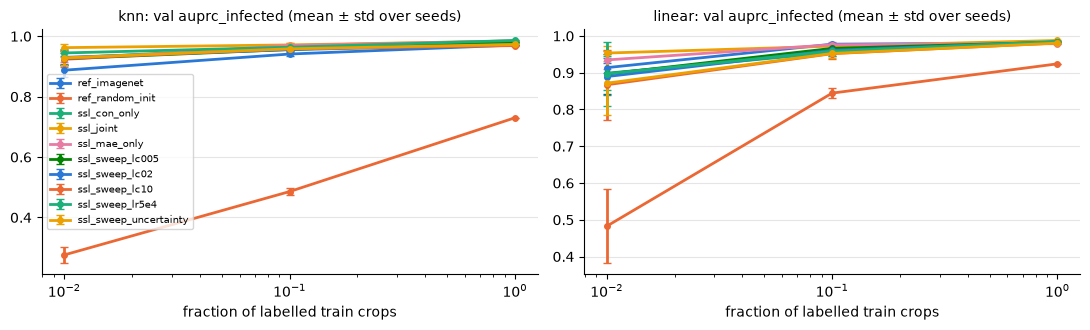

In [14]:
viz.plot_low_label(probes, 'auprc_infected');
viz.low_label_table(probes, 'auprc_infected')

## PCA ембедингів клітин (val), кольори — класи

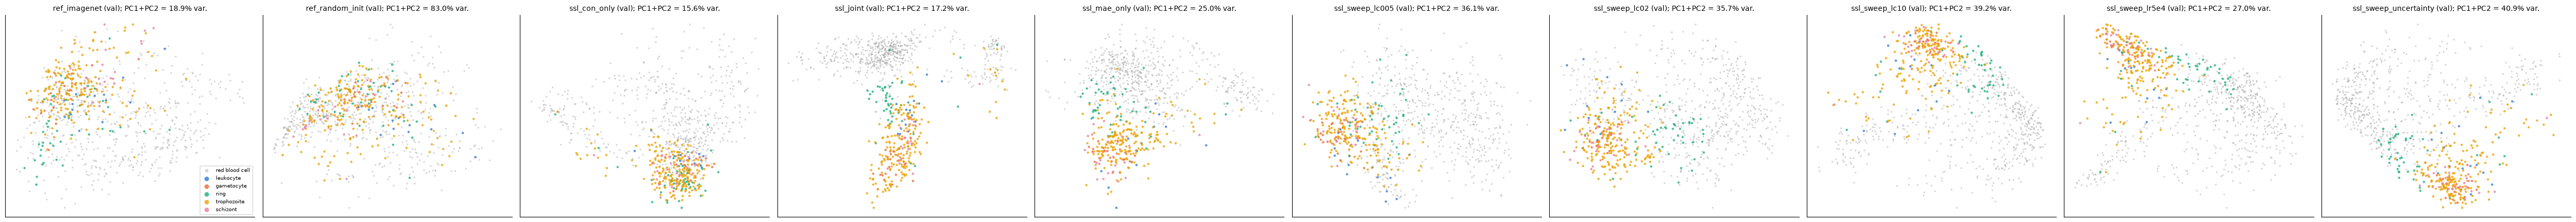

In [15]:
viz.plot_pca([p['tag'] for p in probes], 'val');

## Фінальне порівняння: joint vs mae_only vs con_only (100 епох, λ_con = 0.2, blr 5e-4)

Val-кропи, 100% міток, 95% bootstrap CI по val-зображеннях; 10% міток — mean ± std по 5 seeds. kNN — balanced accuracy (мультиклас; звичайна accuracy в probe не рахується: 2000 з 2312 val-кропів — підвибрані RBC). Та сама таблиця: `reports/tables/phase3_final_comparison.csv` (`scripts/compare_probes.py`).

In [16]:
FINAL = ['ssl_joint', 'ssl_mae_only', 'ssl_con_only']
final_runs = [viz.load_ssl_run(resolve_path('runs') / n) for n in FINAL]
final_probes = viz.load_probes(['ref_random_init', 'ref_imagenet', 'ssl_mae_only', 'ssl_con_only', 'ssl_joint'])
viz.comparison_table(final_probes)

,encoder,linear_auprc_clean,linear_auprc_clean_CI95,linear_auprc_stain,linear_auprc_stain_CI95,linear_auprc_10pct_mean,linear_auprc_10pct_std,linear_macro_f1,linear_macro_f1_CI95,knn_balanced_acc,knn_balanced_acc_CI95
0,ref_random_init,0.924,"[0.883, 0.954]",0.525,"[0.421, 0.638]",0.845,0.015,0.515,"[0.460, 0.567]",0.437,"[0.371, 0.508]"
1,ref_imagenet,0.981,"[0.972, 0.989]",0.943,"[0.921, 0.961]",0.978,0.004,0.646,"[0.589, 0.696]",0.616,"[0.546, 0.686]"
2,ssl_mae_only,0.979,"[0.956, 0.993]",0.946,"[0.922, 0.966]",0.976,0.007,0.705,"[0.655, 0.750]",0.693,"[0.626, 0.755]"
3,ssl_con_only,0.986,"[0.971, 0.996]",0.982,"[0.968, 0.993]",0.954,0.010,0.732,"[0.676, 0.780]",0.759,"[0.685, 0.826]"
4,ssl_joint,0.988,"[0.974, 0.996]",0.984,"[0.971, 0.992]",0.972,0.005,0.728,"[0.671, 0.776]",0.781,"[0.713, 0.843]"


### Парний bootstrap різниць: joint − con_only, joint − mae_only

Обидва енкодери оцінюються на **тих самих** 1000 ресемплах val-зображень (той самий seed, що й у маргінальних CI). Інтервал — 95% percentile CI різниці; `frac_le_0` — частка ресемплів із різницею ≤ 0. Для 10% міток: метрика — середнє по 5 seeds (однакові підвибірки для обох енкодерів); CI враховує лише варіабельність val-зображень, тому нижче показано ще й різниці по кожному seed окремо. Класифікатори перефічено на CPU зі збережених ознак (`scripts/paired_probe_diff.py`). Відхилення від `probe_<tag>.json`: AUPRC ≤ 3.4e-4, kNN — 0, linear macro-F1 — до 3.6e-3 (CPU vs GPU L-BFGS). Поправки на множинні порівняння (10 різниць) немає.

In [17]:
import json
paired = pd.read_csv(resolve_path('reports/tables/phase3_paired_diff.csv'))
display(paired)
per_seed = json.loads(resolve_path('reports/tables/phase3_paired_diff.json').read_text(encoding='utf-8'))['per_seed_diff']
pd.DataFrame(per_seed, index=[f'seed {s}' for s in range(5)]).T

,a,b,metric,value_a,value_b,diff,ci_low,ci_high,frac_le_0,excludes_0
0,ssl_joint,ssl_con_only,auprc_clean,0.988,0.986,0.001,-2.100e-03,0.005,0.266,False
1,ssl_joint,ssl_con_only,auprc_stain,0.984,0.982,0.001,-4.800e-03,0.009,0.390,False
2,ssl_joint,ssl_con_only,auprc_10pct,0.972,0.954,0.018,9.800e-03,0.028,0.000,True
3,ssl_joint,ssl_con_only,macro_f1,0.724,0.734,-0.009,-4.710e-02,0.026,0.711,False
4,ssl_joint,ssl_con_only,knn_balanced_acc,0.781,0.759,0.022,-1.900e-02,0.070,0.153,False
5,ssl_joint,ssl_mae_only,auprc_clean,0.988,0.979,0.009,7.000e-04,0.020,0.011,True
6,ssl_joint,ssl_mae_only,auprc_stain,0.984,0.946,0.038,2.080e-02,0.057,0.000,True
7,ssl_joint,ssl_mae_only,auprc_10pct,0.972,0.976,-0.004,-1.210e-02,0.004,0.837,False
8,ssl_joint,ssl_mae_only,macro_f1,0.724,0.705,0.020,-3.120e-02,0.071,0.227,False
9,ssl_joint,ssl_mae_only,knn_balanced_acc,0.781,0.693,0.088,3.250e-02,0.149,0.000,True


,seed 0,seed 1,seed 2,seed 3,seed 4
ssl_joint - ssl_con_only: auprc_10pct,0.024,0.011,1.021e-02,0.022,0.023
ssl_joint - ssl_mae_only: auprc_10pct,0.011,-0.005,5.046e-04,-0.010,-0.014


### Остання епоха: losses і діагностика колапсу (фіксовані 512 val-пар)

`rep` — середнє патч-токенів енкодера (d = 384), `proj` — вихід projector (d = 256). `std × √d` ≈ 1 — розкид по сфері; erank ≤ d.

In [18]:
viz.final_epoch_table(final_runs)

,run,epoch,loss_mae,val_loss_mae,loss_con,val_loss_con,rep/std_x_sqrt_d,rep/erank,proj/std_x_sqrt_d,proj/erank
0,ssl_joint,99.0,0.169,0.175,1.232,1.383,0.574,119.052,0.996,159.966
1,ssl_mae_only,99.0,0.164,0.170,NaN,NaN,0.123,90.801,NaN,NaN
2,ssl_con_only,99.0,NaN,NaN,1.245,1.395,0.728,118.311,0.997,156.860


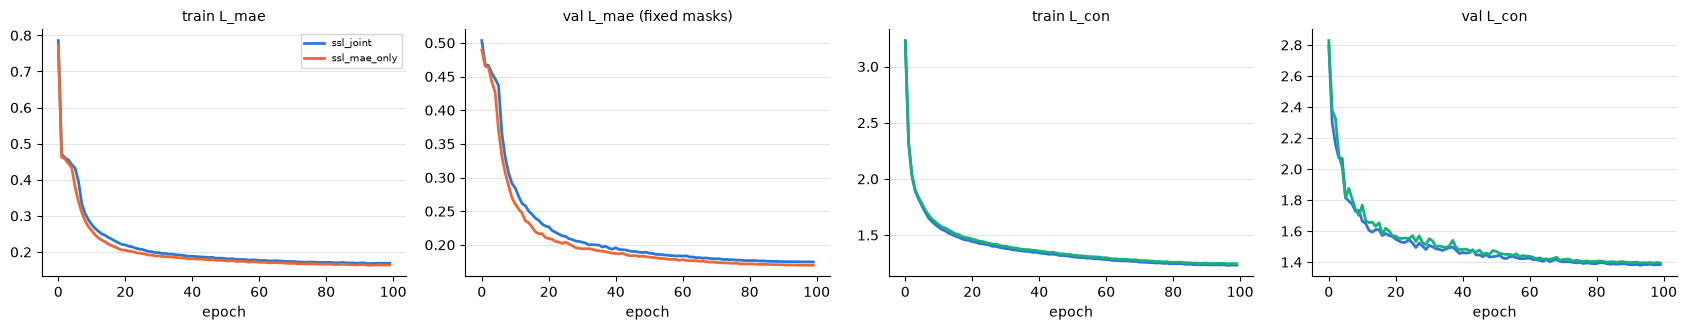

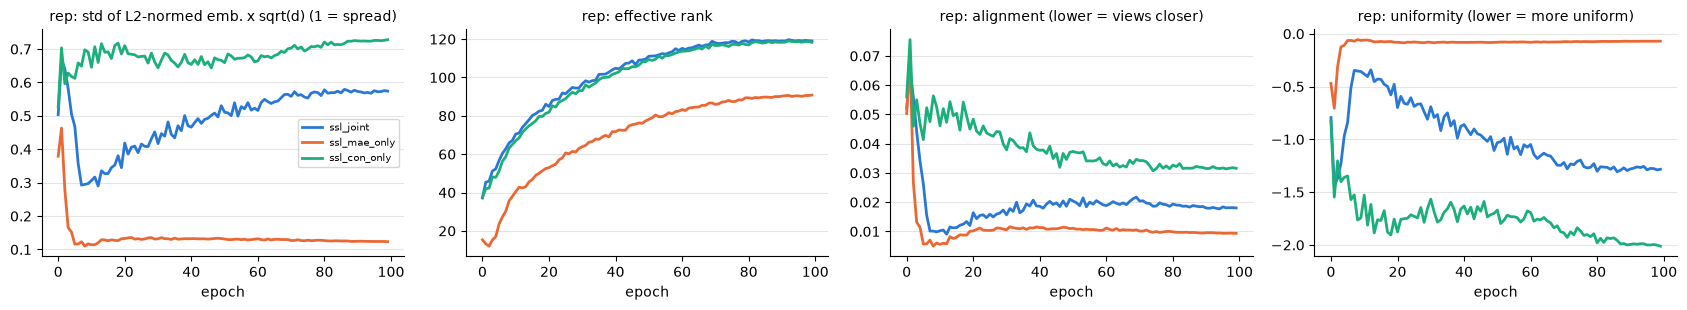

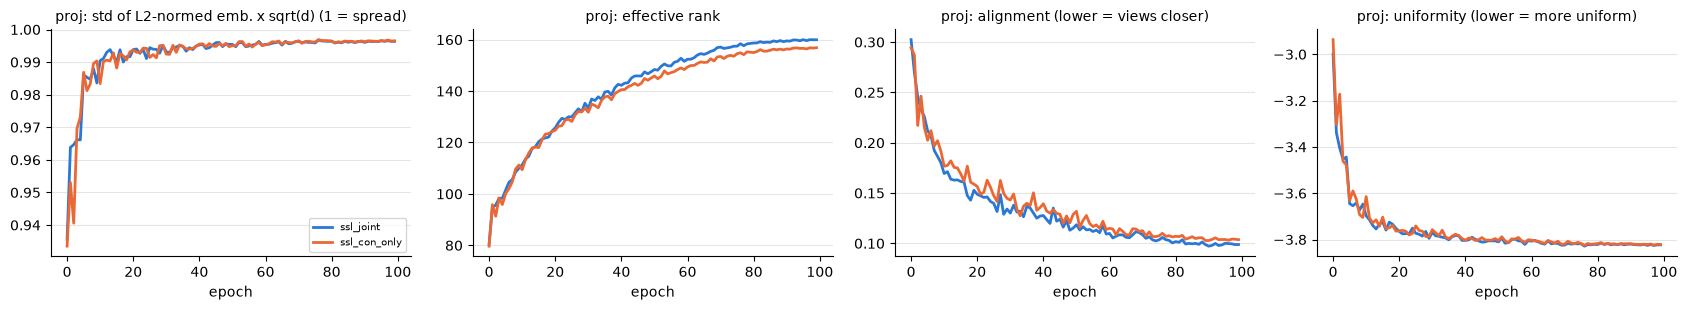

In [19]:
viz.plot_losses(final_runs);
viz.plot_collapse(final_runs, 'rep');
viz.plot_collapse([r for r in final_runs if 'proj/erank' in r['history']], 'proj');

### Реконструкції MAE останньої епохи (рядки: оригінал | маска | реконструкція)

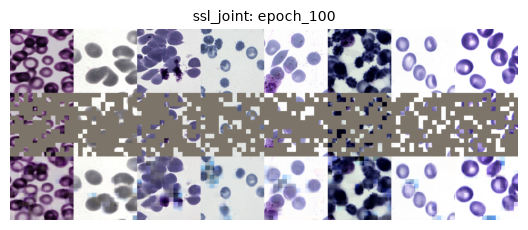

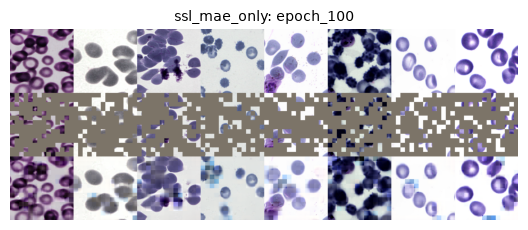

In [20]:
for r in final_runs:
    if r['recon']:
        viz.show_recon(r, (-1,))